# 01 · EDA on the Sparkov 10% card sample

Data: `data/processed/sample_10pct.parquet` (100 cards, all their transactions; build it with
`uv run python -m fraudshield.data --sample 0.1`). The monthly trend uses the full file.

**The dataset is synthetic.** These are properties of the Sparkov generator, not of real card fraud.
Findings are summarised in `docs/DATA.md` under "EDA findings".

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data/processed/sample_10pct.parquet")
base = df["is_fraud"].mean()
print(
    f"{len(df):,} rows, {df['card_id'].nunique()} cards, {df['is_fraud'].sum()} fraud, base rate {base:.3%}"
)


def rate(by):
    """Fraud rate, fraud count and row count per group, plus lift over the base rate."""
    g = df.groupby(by, observed=True)["is_fraud"].agg(rate="mean", fraud="sum", rows="size")
    return g.assign(lift=g["rate"] / base)


def bar(table, title, ax=None):
    ax = ax or plt.subplots(figsize=(9, 3))[1]
    (table["rate"] * 100).plot.bar(ax=ax, color="tab:red")
    ax.axhline(base * 100, ls="--", c="grey", label=f"base {base:.2%}")
    ax.set(title=title, ylabel="fraud rate %", xlabel="")
    ax.legend()
    return ax

185,182 rows, 100 cards, 968 fraud, base rate 0.523%


## 1. Fraud rate over time (full dataset, by month)

event_time,2019-01,2019-02,2019-03,2019-04,2019-05,2019-06,2019-07,2019-08,2019-09,2019-10,...,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12
rate,0.0096,0.0104,0.007,0.0055,0.0056,0.0041,0.0038,0.0044,0.0059,0.0066,...,0.0061,0.0045,0.0071,0.0053,0.0037,0.0047,0.0049,0.0055,0.004,0.0018
rows,52525.0000,49866.0000,70939.000,68078.0000,72532.0000,86064.0000,86596.0000,87359.0000,70652.0000,68758.0000,...,72850.0000,66892.0000,74343.0000,87805.0000,85848.0000,88759.0000,69533.0000,69348.0000,72635.000,139538.0000


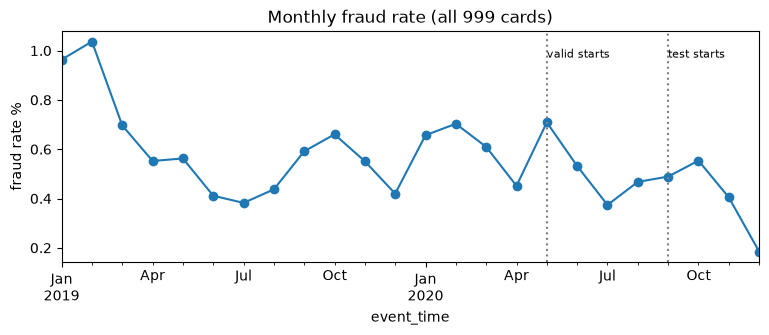

In [2]:
full = pd.read_parquet(ROOT / "data/processed/transactions.parquet", columns=["event_time", "is_fraud"])
monthly = full.groupby(full["event_time"].dt.to_period("M"))["is_fraud"].agg(rate="mean", rows="size")
ax = (monthly["rate"] * 100).plot(figsize=(9, 3), marker="o", title="Monthly fraud rate (all 999 cards)")
ax.set_ylabel("fraud rate %")
for boundary, label in (("2020-05", "valid starts"), ("2020-09", "test starts")):
    ax.axvline(pd.Period(boundary, "M").ordinal, ls=":", c="grey")
    ax.text(pd.Period(boundary, "M").ordinal, ax.get_ylim()[1] * 0.9, label, fontsize=8)
monthly.T.round(4)

## 2. By category

,rate,fraud,rows,lift
category,,,,
health_fitness,0.0015,19,12277,0.2961
food_dining,0.0016,21,13032,0.3083
home,0.0019,33,17570,0.3593
entertainment,0.0019,26,13528,0.3677
personal_care,0.0021,28,13154,0.4072
grocery_net,0.0022,15,6705,0.4280
kids_pets,0.0023,37,16332,0.4334
travel,0.0024,14,5741,0.4665
misc_pos,0.0031,36,11777,0.5848


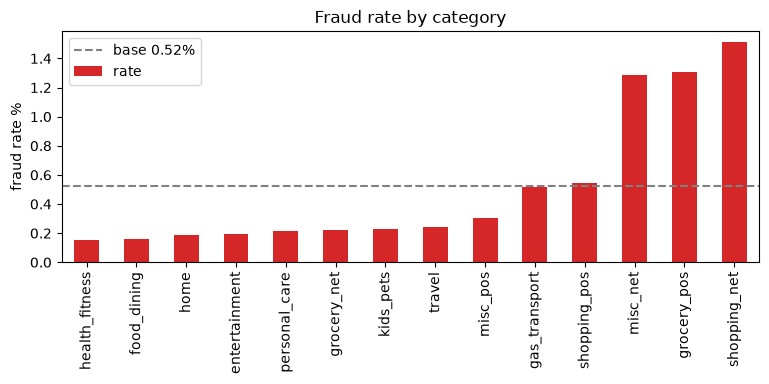

In [3]:
t = rate("category").sort_values("rate")
bar(t, "Fraud rate by category")
t.round(4)

## 3. By hour of day

22:00-03:59: 1.87% of tx are fraud, 83% of all fraud; other hours: 0.114%


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
rate,0.0181,0.0135,0.0118,0.0139,0.0014,0.0012,0.0010,0.0008,0.0011,0.0015,...,0.0006,0.0007,0.0011,0.0010,0.0010,0.0016,0.0012,0.0018,0.0245,0.0239
fraud,109.0000,83.0000,71.0000,84.0000,8.0000,7.0000,6.0000,5.0000,7.0000,9.0000,...,6.0000,7.0000,10.0000,9.0000,10.0000,15.0000,11.0000,17.0000,232.0000,227.0000
rows,6007.0000,6130.0000,6019.0000,6058.0000,5887.0000,5958.0000,5880.0000,6130.0000,6093.0000,5991.0000,...,9311.0000,9370.0000,9387.0000,9439.0000,9634.0000,9414.0000,9239.0000,9489.0000,9451.0000,9512.0000
lift,3.4713,2.5902,2.2566,2.6526,0.2600,0.2248,0.1952,0.1560,0.2198,0.2874,...,0.1233,0.1429,0.2038,0.1824,0.1986,0.3048,0.2278,0.3427,4.6961,4.5654


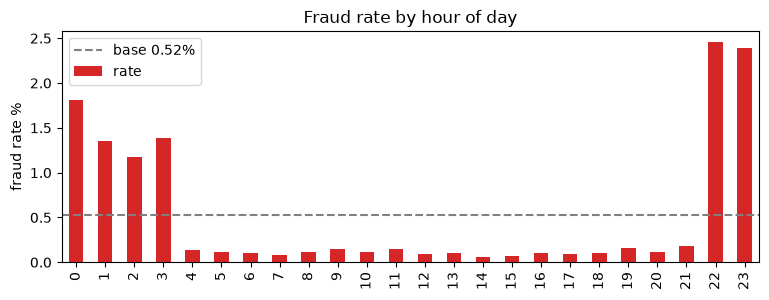

In [4]:
t = rate(df["event_time"].dt.hour.rename("hour"))
bar(t, "Fraud rate by hour of day")
night = df["event_time"].dt.hour.isin([22, 23, 0, 1, 2, 3])
print(
    f"22:00-03:59: {df.loc[night, 'is_fraud'].mean():.2%} of tx are fraud, "
    f"{df.loc[night, 'is_fraud'].sum() / df['is_fraud'].sum():.0%} of all fraud; "
    f"other hours: {df.loc[~night, 'is_fraud'].mean():.3%}"
)
t.round(4).T

## 4. By amount

,rate,fraud,rows,lift
amount,,,,
"(0.0, 10.0]",0.0016,74,45860,0.3087
"(10.0, 50.0]",0.0032,153,47647,0.6143
"(50.0, 100.0]",0.0001,5,57475,0.0166
"(100.0, 200.0]",0.0009,22,25055,0.1680
"(200.0, 300.0]",0.0210,100,4759,4.0198
"(300.0, 500.0]",0.0810,176,2172,15.5016
"(500.0, 1000.0]",0.1963,328,1671,37.5509
"(1000.0, inf]",0.2026,110,543,38.7540


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,184214.0,69.78,168.96,1.00,10.20,49.17,84.06,27390.12
1,968.0,503.61,390.00,5.29,122.85,340.95,883.68,1288.29


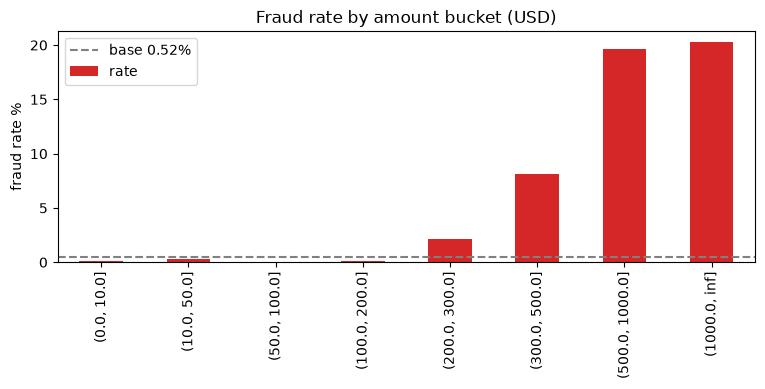

In [5]:
buckets = pd.cut(df["amount"], [0, 10, 50, 100, 200, 300, 500, 1000, np.inf])
t = rate(buckets.rename("amount"))
bar(t, "Fraud rate by amount bucket (USD)")
display(t.round(4))
df.groupby("is_fraud")["amount"].describe().round(2)

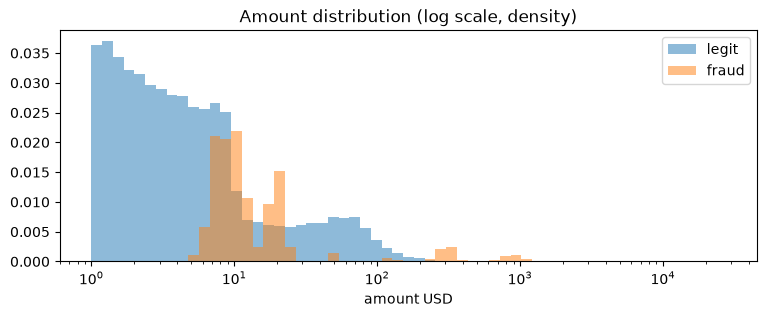

In [6]:
fig, ax = plt.subplots(figsize=(9, 3))
bins = np.logspace(0, np.log10(df["amount"].max()), 60)
for label, d in df.groupby("is_fraud"):
    ax.hist(d["amount"], bins=bins, density=True, alpha=0.5, label=["legit", "fraud"][label])
ax.set(xscale="log", title="Amount distribution (log scale, density)", xlabel="amount USD")
ax.legend();

## 5. Distance from home

Haversine distance between the cardholder's home (`lat`, `lon`) and the merchant (`merch_lat`, `merch_lon`).

,rate,fraud,rows,lift
dist_km decile,,,,
"(0.312, 34.962]",0.0045,84,18519,0.8677
"(34.962, 49.494]",0.0057,105,18518,1.0847
"(49.494, 60.675]",0.0045,84,18518,0.8678
"(60.675, 70.079]",0.0060,112,18518,1.1570
"(70.079, 78.352]",0.0055,102,18518,1.0537
"(78.352, 86.006]",0.0048,88,18518,0.9091
"(86.006, 94.144]",0.0052,97,18518,1.0021
"(94.144, 103.133]",0.0044,81,18518,0.8368
"(103.133, 112.969]",0.0055,101,18518,1.0434


max distance 147 km


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,184214.0,76.2,29.2,0.3,55.4,78.4,98.6,147.1
1,968.0,77.3,28.8,3.6,57.2,78.0,99.4,140.0


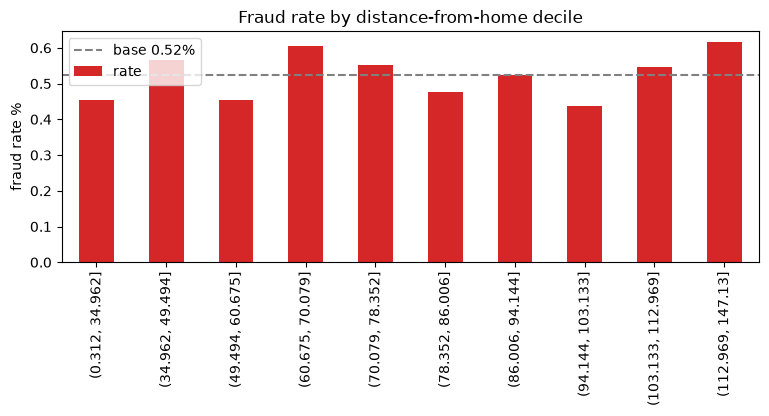

In [7]:
def km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


df["dist_km"] = km(df["lat"], df["lon"], df["merch_lat"], df["merch_lon"])
t = rate(pd.qcut(df["dist_km"], 10).rename("dist_km decile"))
bar(t, "Fraud rate by distance-from-home decile")
display(t.round(4))
print(f"max distance {df['dist_km'].max():.0f} km")
df.groupby("is_fraud")["dist_km"].describe().round(1)

## 6. By age, gender, day of week

,rate,fraud,rows,lift
age,,,,
"(0, 25]",0.0058,123,21217,1.1090
"(25, 35]",0.0045,206,45907,0.8584
"(35, 50]",0.0039,242,61965,0.7471
"(50, 65]",0.0069,330,48025,1.3145
"(65, 120]",0.0083,67,8068,1.5887


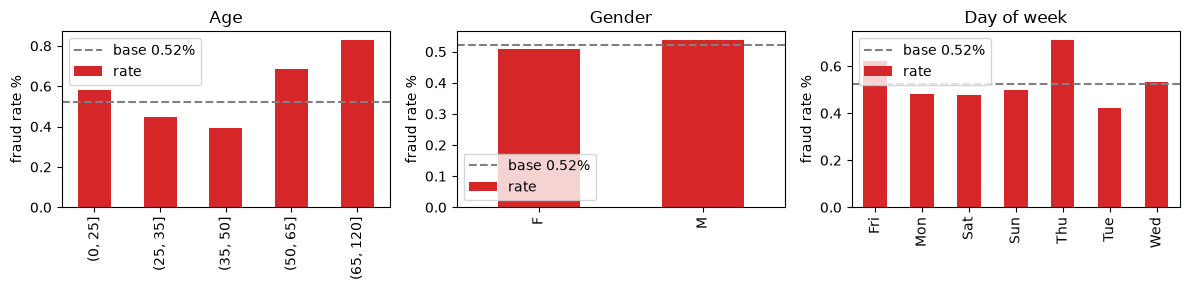

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
bar(rate(pd.cut(df["age"], [0, 25, 35, 50, 65, 120]).rename("age")), "Age", axes[0])
bar(rate("gender"), "Gender", axes[1])
bar(rate(df["event_time"].dt.day_name().str[:3].rename("dow")), "Day of week", axes[2])
plt.tight_layout()
rate(pd.cut(df["age"], [0, 25, 35, 50, 65, 120]).rename("age")).round(4)

## 7. How fraud arrives per card

Velocity features only help if fraud comes in episodes. How many cards are hit, how long does an
episode last, and how fast do fraud transactions follow each other?

In [9]:
fraud = df[df["is_fraud"] == 1]
per_card = fraud.groupby("card_id")["event_time"].agg(n="size", first="min", last="max")
per_card["span_h"] = (per_card["last"] - per_card["first"]).dt.total_seconds() / 3600
gaps_min = fraud.groupby("card_id")["event_time"].diff().dt.total_seconds().dropna() / 60
print(f"cards with any fraud: {len(per_card)} of {df['card_id'].nunique()}")
print(f"fraud tx per hit card: median {per_card['n'].median():.0f}, max {per_card['n'].max()}")
print(
    f"episode span (first to last fraud tx): median {per_card['span_h'].median():.1f} h, "
    f"max {per_card['span_h'].max():.1f} h"
)
print(
    f"gap between consecutive fraud tx on a card: median {gaps_min.median():.0f} min, "
    f"90th pct {gaps_min.quantile(0.9):.0f} min"
)

legit_gaps = df[df["is_fraud"] == 0].groupby("card_id")["event_time"].diff().dt.total_seconds().dropna() / 60
print(f"gap between consecutive legit tx on a card: median {legit_gaps.median():.0f} min")

cards with any fraud: 99 of 100
fraud tx per hit card: median 10, max 16
episode span (first to last fraud tx): median 45.2 h, max 47.7 h
gap between consecutive fraud tx on a card: median 69 min, 90th pct 1081 min
gap between consecutive legit tx on a card: median 272 min
